## Setup and Imports

In [1]:
# Title: Importsimport sysfrom pathlib import Path# Add parent directory to path for importsPROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()if str(PROJECT_ROOT) not in sys.path:    sys.path.insert(0, str(PROJECT_ROOT))import laspyimport numpy as npimport pandas as pdfrom pyntcloud import PyntCloudimport matplotlib.pyplot as pltprint(f"✅ Project root: {PROJECT_ROOT}")print(f"✅ All imports successful")

✅ Project root: /home/nvidia/projects/fvc_structure/phase_5_3d_cnn_training
✅ All imports successful


## Configuration

In [2]:
# Title: Input directory containing LAS files with structure + treeID# Input directory containing LAS files with structure + treeIDINPUT_DIR = Path("/data/calperumResearch/site1_1_DD0001/lidar/clipped/3d_structure_mask_malleid")# Output directoriesOUT_NPZ_DIR = Path("/data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/minsu3d_npz/")OUT_PLY_DIR = Path("/data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/forestformer3d_ply/")OUT_NPZ_DIR.mkdir(parents=True, exist_ok=True)OUT_PLY_DIR.mkdir(parents=True, exist_ok=True)# Processing parametersVOXEL_SIZE = 0.10  # 10 cm voxelsIGNORE_INDEX = -100  # PyTorch convention for ignored labels# Class mapping: LAS classification codes -> model class IDsCLASS_REMAP = {    64: 0,  # Forb    65: 1,  # Woody debris    66: 2,  # Hummock    67: 3,  # Shrub    68: 4,  # Mallee    0: IGNORE_INDEX,  # Unmatched / background}print(f"📂 Input:  {INPUT_DIR}")print(f"📂 NPZ:    {OUT_NPZ_DIR}")print(f"📂 PLY:    {OUT_PLY_DIR}")print(f"📐 Voxel size: {VOXEL_SIZE} m")print(f"🏷️  Classes: {len([k for k in CLASS_REMAP if CLASS_REMAP[k] != IGNORE_INDEX])}")

📂 Input:  /data/calperumResearch/site1_1_DD0001/lidar/clipped/3d_structure_mask_malleid
📂 NPZ:    /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/minsu3d_npz
📂 PLY:    /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/forestformer3d_ply
📐 Voxel size: 0.1 m
🏷️  Classes: 5


## Preprocessing Functions

In [3]:
# Title: Def: normalise_intensitydef normalise_intensity(intensity):    """Normalise intensity to [0, 1] range, handling 8/16-bit data."""    intensity = intensity.astype(np.float32)    if intensity.size == 0:        return intensity        max_val = float(intensity.max())    if max_val <= 0:        return np.zeros_like(intensity, dtype=np.float32)        # Auto-detect bit depth    if max_val <= 255:        scale = 255.0    elif max_val <= 65535:        scale = 65535.0    else:        scale = max_val        return np.clip(intensity / scale, 0.0, 1.0)def get_z_norm(las, raw_xyz):    """Extract or compute normalized height (Z_norm)."""    dims = las.point_format.dimension_names    if "Z_norm" in dims:        return las["Z_norm"].astype(np.float32)    # Fallback: relative height within tile    z = raw_xyz[:, 2]    return (z - z.min()).astype(np.float32)def remap_classes(raw_labels):    """Remap LAS classification codes to compact class IDs."""    sem = np.full_like(raw_labels, IGNORE_INDEX, dtype=np.int32)    for old, new in CLASS_REMAP.items():        sem[raw_labels == old] = new    return semdef get_tree_ids(las, n, fname):    """Extract tree instance IDs from LAS extra dimensions."""    dims = las.point_format.dimension_names    if "treeID" in dims:        return las["treeID"].astype(np.int32)    print(f"⚠️ Warning: no treeID in {fname}, using zeros.")    return np.zeros(n, dtype=np.int32)def write_forestformer_ply(out_path, xyz_abs, semantic, inst, z_norm, intensity):    """Write PLY file for ForestFormer3D, excluding ignore-index points.        Important: xyz_abs must contain ABSOLUTE coordinates (global CRS) from the original LAS.    This ensures PLY files can be directly converted back to LAS without coordinate transformation.    """    valid_mask = semantic != IGNORE_INDEX    n_valid = int(valid_mask.sum())        if n_valid == 0:        print(f"⚠️ No valid points for {out_path.name}, skipping PLY.")        return        # Verify coordinates are in global space (sanity check)    coord_min = xyz_abs[valid_mask].min(axis=0)    coord_max = xyz_abs[valid_mask].max(axis=0)        df = pd.DataFrame({        "x": xyz_abs[valid_mask, 0],        "y": xyz_abs[valid_mask, 1],        "z": xyz_abs[valid_mask, 2],        "semantic_seg": semantic[valid_mask],        "treeID": inst[valid_mask],        "z_norm": z_norm[valid_mask],        "intensity": intensity[valid_mask],    })    cloud = PyntCloud(df)    cloud.to_file(str(out_path))        # Log coordinate range for verification    print(f"  PLY coords: X[{coord_min[0]:.1f}, {coord_max[0]:.1f}] "          f"Y[{coord_min[1]:.1f}, {coord_max[1]:.1f}] "          f"Z[{coord_min[2]:.1f}, {coord_max[2]:.1f}]")print("✅ Preprocessing functions loaded")

✅ Preprocessing functions loaded


## Main Processing Function

In [ ]:
# Title: def process_las(path: Path):# def process_las(path: Path):#     """Process single LAS file into NPZ (MINSU3D) and PLY (ForestFormer3D)."""#     print(f"📦 Processing {path.name}")#     las = laspy.read(path)    #     # Extract XYZ coordinates#     raw_xyz = np.vstack([las.x, las.y, las.z]).T#     if raw_xyz.size == 0:#         raise ValueError("Empty point cloud.")    #     # Local coordinate shift#     offset = raw_xyz.min(axis=0)#     xyz_local = raw_xyz - offset    #     # Extract features#     intensity = normalise_intensity(las.intensity)#     z_norm = get_z_norm(las, raw_xyz)#     feats = np.column_stack([xyz_local, z_norm, intensity]).astype(np.float32)    #     # Extract labels#     raw_labels = las.classification.astype(np.int32)#     semantic = remap_classes(raw_labels)#     inst = get_tree_ids(las, len(raw_labels), path.name)    #     # Compute voxel coordinates#     coords = np.floor(xyz_local / VOXEL_SIZE).astype(np.int32)    #     # Preserve original LAS header information for reconstruction#     header_offset = np.array(las.header.offsets, dtype=np.float64)#     header_scale = np.array(las.header.scales, dtype=np.float64)    #     # Save NPZ (MINSU3D format)#     npz_path = OUT_NPZ_DIR / f"{path.stem}.npz"#     np.savez_compressed(#         npz_path,#         coords=coords,#         feats=feats,#         semantic_label=semantic,#         instance_label=inst,#         offset=offset.astype(np.float64),#         header_offset=header_offset,  # Original LAS header offset#         header_scale=header_scale,    # Original LAS header scale#     )    #     # Save PLY (ForestFormer3D format) with ABSOLUTE coordinates#     # Important: Use raw_xyz (not xyz_local) to preserve global coordinate system#     # This ensures PLY files can be converted back to LAS without coordinate alignment#     ply_path = OUT_PLY_DIR / f"{path.stem}.ply"#     write_forestformer_ply(#         ply_path,#         xyz_abs=raw_xyz,  # Original absolute coords from LAS file#         semantic=semantic,#         inst=inst,#         z_norm=z_norm,#         intensity=intensity,#     )    #     return npz_path, ply_path# print("✅ Main processing function loaded")

✅ Main processing function loaded


In [4]:
# Title: test 2: good#test 2: goodfrom pathlib import Pathimport numpy as npimport laspydef process_las(path: Path):    """Process single LAS file into NPZ (MINSU3D) and PLY (ForestFormer3D)."""    print(f"📦 Processing {path.name}")    las = laspy.read(path)    # --- absolute coords from LAS (float64) ---    raw_xyz = np.vstack([las.x, las.y, las.z]).T.astype(np.float64)    if raw_xyz.size == 0:        raise ValueError("Empty point cloud.")    # --- Local coordinate shift ---    offset = raw_xyz.min(axis=0).astype(np.float64)    xyz_local = (raw_xyz - offset).astype(np.float32)    # --- features ---    intensity = normalise_intensity(las.intensity).astype(np.float32)    z_norm = get_z_norm(las, raw_xyz).astype(np.float32)    feats = np.column_stack([xyz_local, z_norm, intensity]).astype(np.float32)    # --- labels ---    raw_labels = las.classification.astype(np.int32)    semantic = remap_classes(raw_labels).astype(np.int32)    inst = get_tree_ids(las, len(raw_labels), path.name).astype(np.int32)    # --- voxel coords for MINSU3D ---    coords = np.floor(xyz_local / VOXEL_SIZE).astype(np.int32)    # --- preserve header for LAS reconstruction ---    header_offset = np.array(las.header.offsets, dtype=np.float64)    header_scale  = np.array(las.header.scales, dtype=np.float64)    # ---------------- NPZ (MINSU3D) ----------------    npz_path = OUT_NPZ_DIR / f"{path.stem}.npz"    np.savez_compressed(        npz_path,        coords=coords,        feats=feats,        semantic_label=semantic,        instance_label=inst,        offset=offset.astype(np.float64),        header_offset=header_offset,        header_scale=header_scale,    )    # ---------------- PLY (ForestFormer3D raw input) ----------------    # Write *LOCAL* coords to avoid float32 precision collapse.    ply_path = OUT_PLY_DIR / f"{path.stem}.ply"    write_forestformer_ply(        ply_path,        xyz_abs=xyz_local,          # <-- intentionally local coords        semantic=semantic,        inst=inst,        z_norm=z_norm,        intensity=intensity,    )    # Sidecar: store the offset so you can recover global coords if needed    np.save(OUT_PLY_DIR / f"{path.stem}_offset.npy", offset.astype(np.float64))    return npz_path, ply_path

In [5]:
# Title: Importsfrom pathlib import Path# Pick one LASsample_las = Path(    "/data/calperumResearch/site1_1_DD0001/lidar/clipped/3d_structure_mask_malleid/znorm_3Dlabels_106.las")npz_path, ply_path = process_las(sample_las)print("NPZ:", npz_path)print("PLY:", ply_path)

📦 Processing znorm_3Dlabels_106.las


  PLY coords: X[0.0, 30.7] Y[0.0, 30.7] Z[0.0, 4.9]
NPZ: /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/minsu3d_npz/znorm_3Dlabels_106.npz
PLY: /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/forestformer3d_ply/znorm_3Dlabels_106.ply


## Batch Processing

In [8]:
# Title: Find all LAS files# Find all LAS fileslas_files = sorted(INPUT_DIR.glob("*.las"))if not las_files:    print("❌ No LAS files found.")else:    print(f"🚀 Found {len(las_files)} LAS files.")    print("\nFirst 5 files:")    for f in las_files[:5]:        print(f"   {f.name}")

🚀 Found 15 LAS files.

First 5 files:
   znorm_3Dlabels_106.las
   znorm_3Dlabels_109.las
   znorm_3Dlabels_113.las
   znorm_3Dlabels_121.las
   znorm_3Dlabels_16.las


In [9]:
# Title: Process all files# Process all filesall_npz = []all_ply = []errors = []for f in las_files:    try:        npz, ply = process_las(f)        all_npz.append(str(npz))        all_ply.append(str(ply))    except Exception as e:        print(f"❌ Error in {f.name}: {e}")        errors.append((f.name, str(e)))# Save file listswith open(OUT_NPZ_DIR / "npz_list.txt", "w") as f:    f.write("\n".join(all_npz))with open(OUT_PLY_DIR / "ply_list.txt", "w") as f:    f.write("\n".join(all_ply))print(f"\n✅ Processing complete!")print(f"   Successful: {len(all_npz)} files")print(f"   Errors: {len(errors)} files")print(f"\n📄 NPZ list: {OUT_NPZ_DIR / 'npz_list.txt'}")print(f"📄 PLY list: {OUT_PLY_DIR / 'ply_list.txt'}")if errors:    print("\n⚠️ Errors encountered:")    for fname, err in errors:        print(f"   {fname}: {err}")

📦 Processing znorm_3Dlabels_106.las


  PLY coords: X[0.0, 30.7] Y[0.0, 30.7] Z[0.0, 4.9]
📦 Processing znorm_3Dlabels_109.las
  PLY coords: X[0.0, 30.7] Y[0.0, 30.7] Z[0.0, 5.6]
📦 Processing znorm_3Dlabels_113.las
  PLY coords: X[0.0, 30.7] Y[0.0, 30.7] Z[0.0, 5.2]
📦 Processing znorm_3Dlabels_121.las
  PLY coords: X[0.0, 30.7] Y[0.0, 30.7] Z[0.0, 6.7]
📦 Processing znorm_3Dlabels_16.las
  PLY coords: X[0.0, 30.7] Y[0.0, 30.7] Z[0.0, 4.6]
📦 Processing znorm_3Dlabels_182.las
  PLY coords: X[0.0, 30.7] Y[0.0, 30.7] Z[0.0, 7.2]
📦 Processing znorm_3Dlabels_192.las
  PLY coords: X[0.0, 30.7] Y[0.0, 30.7] Z[0.0, 6.1]
📦 Processing znorm_3Dlabels_205.las
  PLY coords: X[0.0, 30.8] Y[0.0, 30.8] Z[0.0, 8.9]
📦 Processing znorm_3Dlabels_22.las
  PLY coords: X[0.0, 30.7] Y[0.0, 30.7] Z[0.0, 6.0]
📦 Processing znorm_3Dlabels_26.las
  PLY coords: X[0.0, 30.7] Y[0.0, 30.7] Z[0.0, 7.1]
📦 Processing znorm_3Dlabels_55.las
  PLY coords: X[0.0, 30.7] Y[0.0, 30.7] Z[0.0, 5.9]
📦 Processing znorm_3Dlabels_65.las
  PLY coords: X[0.0, 30.7] Y[0.0, 30.

## Validation: Inspect NPZ Output (MINSU3D)

In [10]:
# Title: Load and inspect a sample NPZ file# Load and inspect a sample NPZ fileif all_npz:    sample_npz = Path(all_npz[0])    print(f"📂 Inspecting: {sample_npz.name}\n")        data = np.load(sample_npz)        print(f"Keys: {list(data.keys())}\n")        coords = data['coords']    feats = data['feats']    semantic_label = data['semantic_label']    instance_label = data['instance_label']    offset = data['offset']        print(f"Total points: {coords.shape[0]:,}")    print(f"Coords shape: {coords.shape} (voxel indices)")    print(f"Feats shape:  {feats.shape} (x, y, z, z_norm, intensity)")    print(f"Offset:       {offset}\n")        print(f"Unique classes: {np.unique(semantic_label)}")    print(f"Class distribution:")    unique, counts = np.unique(semantic_label, return_counts=True)    for cls, cnt in zip(unique, counts):        if cls == IGNORE_INDEX:            print(f"  {cls:3d} (IGNORE): {cnt:,} points")        else:            print(f"  {cls:3d}         : {cnt:,} points")        print(f"\nUnique tree IDs: {len(np.unique(instance_label))}")    print(f"Sample tree IDs: {np.unique(instance_label)[:10]}")

📂 Inspecting: znorm_3Dlabels_106.npz

Keys: ['coords', 'feats', 'semantic_label', 'instance_label', 'offset', 'header_offset', 'header_scale']

Total points: 265,168
Coords shape: (265168, 3) (voxel indices)
Feats shape:  (265168, 5) (x, y, z, z_norm, intensity)
Offset:       [4.6167947e+05 6.2375062e+06 5.7830000e+01]

Unique classes: [2 3 4]
Class distribution:
    2         : 12,371 points
    3         : 599 points
    4         : 252,198 points

Unique tree IDs: 66
Sample tree IDs: [0 1 2 3 4 5 6 7 8 9]


In [11]:
# Title: Create DataFrame view of NPZ data# Create DataFrame view of NPZ dataif all_npz:    combined_data = np.hstack([        coords,         feats,         semantic_label.reshape(-1, 1),         instance_label.reshape(-1, 1)    ])        col_names = [        "vox_x", "vox_y", "vox_z",        "loc_x", "loc_y", "loc_z", "z_norm", "intensity",        "class_id",        "tree_id"    ]        df_npz = pd.DataFrame(combined_data, columns=col_names)        print("Sample rows from NPZ data:\n")    print(df_npz.head(10))        print(f"\nData types:")    print(df_npz.dtypes)

Sample rows from NPZ data:

   vox_x  vox_y  vox_z      loc_x  loc_y  loc_z        z_norm  intensity  \
0  258.0    0.0    6.0  25.799999   0.05   0.68  0.000000e+00   0.231373   
1  277.0    0.0    7.0  27.770000   0.01   0.72  4.471713e-07   0.176471   
2  257.0    1.0    7.0  25.730000   0.13   0.70  1.816984e-02   0.231373   
3  277.0    0.0    7.0  27.709999   0.06   0.71  4.471824e-07   0.172549   
4  287.0    0.0    7.0  28.780001   0.00   0.76  1.210322e-02   0.235294   
5  214.0    0.0    6.0  21.469999   0.03   0.66  2.288326e-02   0.145098   
6  273.0    0.0    7.0  27.379999   0.09   0.70  7.105427e-15   0.168627   
7  210.0    0.0   11.0  21.030001   0.01   1.12  4.930632e-01   0.113725   
8  212.0    0.0    6.0  21.299999   0.04   0.68  5.033479e-02   0.152941   
9  287.0    0.0    7.0  28.750000   0.09   0.75  6.324155e-07   0.231373   

   class_id  tree_id  
0       2.0      0.0  
1       2.0      0.0  
2       2.0      0.0  
3       2.0      0.0  
4       2.0      0.0

## Validation: Inspect PLY Output (ForestFormer3D)

In [17]:
# Title: Load and inspect a sample PLY file# Load and inspect a sample PLY fileif all_ply:    sample_ply = Path(all_ply[0])    print(f"📂 Inspecting: {sample_ply.name}\n")        cloud = PyntCloud.from_file(str(sample_ply))    df_ply = cloud.points        print(f"Total points: {len(df_ply):,}")    print(f"Columns: {df_ply.columns.tolist()}\n")        print("Sample rows:\n")    print(df_ply.head(10))        print(f"\nData types:")    print(df_ply.dtypes)        print(f"\nValue ranges:")    print(f"  X: [{df_ply['x'].min():.2f}, {df_ply['x'].max():.2f}]")    print(f"  Y: [{df_ply['y'].min():.2f}, {df_ply['y'].max():.2f}]")    print(f"  Z: [{df_ply['z'].min():.2f}, {df_ply['z'].max():.2f}]")    print(f"  z_norm: [{df_ply['z_norm'].min():.2f}, {df_ply['z_norm'].max():.2f}]")    print(f"  intensity: [{df_ply['intensity'].min():.3f}, {df_ply['intensity'].max():.3f}]")        print(f"\nClass distribution:")    print(df_ply['semantic_seg'].value_counts().sort_index())

📂 Inspecting: znorm_3Dlabels_106.ply

Total points: 265,168
Columns: ['x', 'y', 'z', 'semantic_seg', 'treeID', 'z_norm', 'intensity']

Sample rows:

           x     y     z  semantic_seg  treeID        z_norm  intensity
0  25.799999  0.05  0.68             2       0  0.000000e+00   0.231373
1  27.770000  0.01  0.72             2       0  4.471713e-07   0.176471
2  25.730000  0.13  0.70             2       0  1.816984e-02   0.231373
3  27.709999  0.06  0.71             2       0  4.471824e-07   0.172549
4  28.780001  0.00  0.76             2       0  1.210322e-02   0.235294
5  21.469999  0.03  0.66             4       0  2.288326e-02   0.145098
6  27.379999  0.09  0.70             2       0  7.105427e-15   0.168627
7  21.030001  0.01  1.12             4       0  4.930632e-01   0.113725
8  21.299999  0.04  0.68             4       0  5.033479e-02   0.152941
9  28.750000  0.09  0.75             2       0  6.324155e-07   0.231373

Data types:
x               float32
y               float3

In [18]:
# Title: Importsimport numpy as npimport laspyfrom pyntcloud import PyntClouddef check_las(las_path):    las = laspy.read(str(las_path))    xyz = np.c_[las.x, las.y, las.z]    print("LAS:", las_path)    print("  XYZ min:", xyz.min(axis=0))    print("  XYZ max:", xyz.max(axis=0))    print("  XYZ range:", xyz.max(axis=0) - xyz.min(axis=0))    print("  Z std:", xyz[:,2].std())def check_ply(ply_path):    df = PyntCloud.from_file(str(ply_path)).points    xyz = df[["x","y","z"]].to_numpy(float)    print("PLY:", ply_path)    print("  XYZ min:", xyz.min(axis=0))    print("  XYZ max:", xyz.max(axis=0))    print("  XYZ range:", xyz.max(axis=0) - xyz.min(axis=0))    print("  Z std:", xyz[:,2].std())    if "z_norm" in df.columns:        zn = df["z_norm"].to_numpy(float)        print("  z_norm range:", (zn.min(), zn.max()))from pathlib import Path# --- set paths (edit if needed) ---las_orig = Path("/data/calperumResearch/site1_1_DD0001/lidar/clipped/3d_structure_mask_malleid/znorm_3Dlabels_106.las")las_from_npz = Path("/home/nvidia/projects/fvc_structure/phase_5_3d_cnn_training/voxel_data_ready/znorm_3Dlabels_106_from_npz.las")las_from_ply = Path("/data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/reconstructed_las/znorm_3Dlabels_106_from_ply.las")ply_in = Path("/data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/forestformer3d_ply/znorm_3Dlabels_106.ply")# --- run checks ---if las_orig.exists():    check_las(las_orig)if las_from_npz.exists():    check_las(las_from_npz)if las_from_ply.exists():    check_las(las_from_ply)if ply_in.exists():    check_ply(ply_in)

LAS: /data/calperumResearch/site1_1_DD0001/lidar/clipped/3d_structure_mask_malleid/znorm_3Dlabels_106.las
  XYZ min: [4.6167947e+05 6.2375062e+06 5.7830000e+01]
  XYZ max: [4.6171017e+05 6.2375369e+06 6.2750000e+01]
  XYZ range: [30.7  30.7   4.92]
  Z std: 0.859190818109963
LAS: /home/nvidia/projects/fvc_structure/phase_5_3d_cnn_training/voxel_data_ready/znorm_3Dlabels_106_from_npz.las
  XYZ min: [4.6167947e+05 6.2375062e+06 5.7830000e+01]
  XYZ max: [4.6171017e+05 6.2375369e+06 6.2750000e+01]
  XYZ range: [30.7  30.7   4.92]
  Z std: 0.859190818109963
LAS: /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/reconstructed_las/znorm_3Dlabels_106_from_ply.las
  XYZ min: [4.6167947e+05 6.2375062e+06 5.7830000e+01]
  XYZ max: [4.6171017e+05 6.2375369e+06 6.2750000e+01]
  XYZ range: [30.7  30.7   4.92]
  Z std: 0.859190818109963
PLY: /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/forestformer3d_ply/znorm_3Dlabels_106.ply
  XYZ min: [0. 0. 0.]
  XYZ max: [30.7

## Visualization: Class Distribution

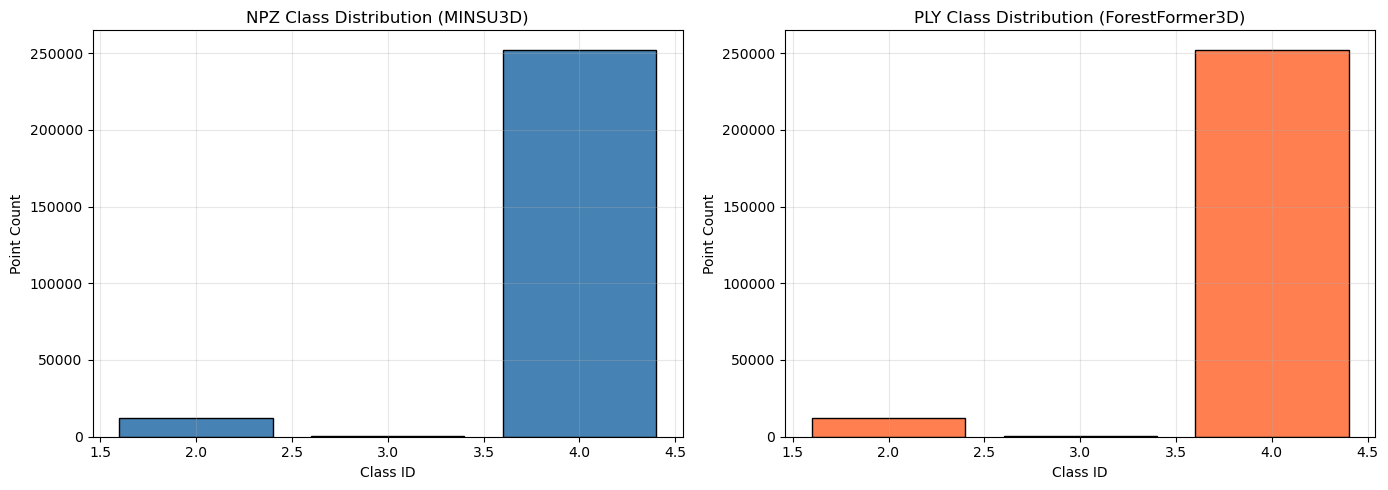

✅ Both formats should show identical class distributions
   (NPZ includes IGNORE_INDEX points, PLY excludes them)


In [14]:
# Title: Code: if all_ply:if all_ply:    fig, axes = plt.subplots(1, 2, figsize=(14, 5))        # Class distribution from NPZ    unique, counts = np.unique(semantic_label[semantic_label != IGNORE_INDEX], return_counts=True)    axes[0].bar(unique, counts, color='steelblue', edgecolor='black')    axes[0].set_xlabel('Class ID')    axes[0].set_ylabel('Point Count')    axes[0].set_title('NPZ Class Distribution (MINSU3D)')    axes[0].grid(True, alpha=0.3)        # Class distribution from PLY    class_counts = df_ply['semantic_seg'].value_counts().sort_index()    axes[1].bar(class_counts.index, class_counts.values, color='coral', edgecolor='black')    axes[1].set_xlabel('Class ID')    axes[1].set_ylabel('Point Count')    axes[1].set_title('PLY Class Distribution (ForestFormer3D)')    axes[1].grid(True, alpha=0.3)        plt.tight_layout()    plt.show()        print("✅ Both formats should show identical class distributions")    print("   (NPZ includes IGNORE_INDEX points, PLY excludes them)")

## Summary Statistics Across All Files

In [15]:
# Title: Aggregate statistics from all processed files# Aggregate statistics from all processed filesif all_npz:    total_points = 0    total_trees = set()    class_counts_global = {}        print("Analyzing all NPZ files...\n")        for npz_path in all_npz:        data = np.load(npz_path)        sem = data['semantic_label']        inst = data['instance_label']                total_points += len(sem)        total_trees.update(inst[inst > 0])  # Count non-zero tree IDs                unique, counts = np.unique(sem, return_counts=True)        for cls, cnt in zip(unique, counts):            class_counts_global[cls] = class_counts_global.get(cls, 0) + cnt        print(f"📊 Dataset Statistics:")    print(f"   Total files: {len(all_npz)}")    print(f"   Total points: {total_points:,}")    print(f"   Unique trees: {len(total_trees)}")    print(f"\n   Global class distribution:")    for cls in sorted(class_counts_global.keys()):        cnt = class_counts_global[cls]        pct = 100 * cnt / total_points        if cls == IGNORE_INDEX:            print(f"     {cls:3d} (IGNORE): {cnt:>12,} ({pct:5.2f}%)")        else:            print(f"     {cls:3d}         : {cnt:>12,} ({pct:5.2f}%)")

Analyzing all NPZ files...



📊 Dataset Statistics:
   Total files: 15
   Total points: 7,951,921
   Unique trees: 78

   Global class distribution:
       2         :    1,326,171 (16.68%)
       3         :      313,674 ( 3.94%)
       4         :    6,312,076 (79.38%)


In [ ]:
# Title: Scratchpad (cell 24)